# 01 – Data exploration

What does a battery at a commercial site in Germany have to work with? This notebook loads the inputs
used throughout the project and looks at the features that matter for scheduling:

* **DE-LU day-ahead prices** (Energy-Charts / SMARD), hourly until 30 Sep 2025 and quarter-hourly since
  the SDAC 15-minute go-live on 1 Oct 2025,
* a **synthetic C&I site**: BDEW G0 load profile (1 GWh/yr) and 400 kWp rooftop PV shaped like
  national German solar output.

Run `uv run fetch-data` once to fill the local cache.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from arbitrage import data, plotting
from arbitrage.site import SiteConfig, build_site_timeseries

plotting.use_style()
C = plotting.COLORS

site = SiteConfig()
df = build_site_timeseries("2023-01-01", "2026-10-21", site)
df.describe().round(1)

,price_eur_mwh,load_kw,pv_kw
count,133436.0,133436.0,133436.0
mean,92.8,113.9,44.5
std,56.5,58.4,66.4
min,-500.0,41.6,0.0
25%,67.2,68.1,0.0
50%,94.2,85.0,1.3
75%,120.6,173.2,74.3
max,936.3,240.2,300.0


## Prices: resolution switch and negative prices

Hourly prices are expanded to four identical quarter hours (exact, not an interpolation). Since October
2025 each quarter hour clears separately, so the price has visible intra-hour steps — extra structure
a fast battery can trade.

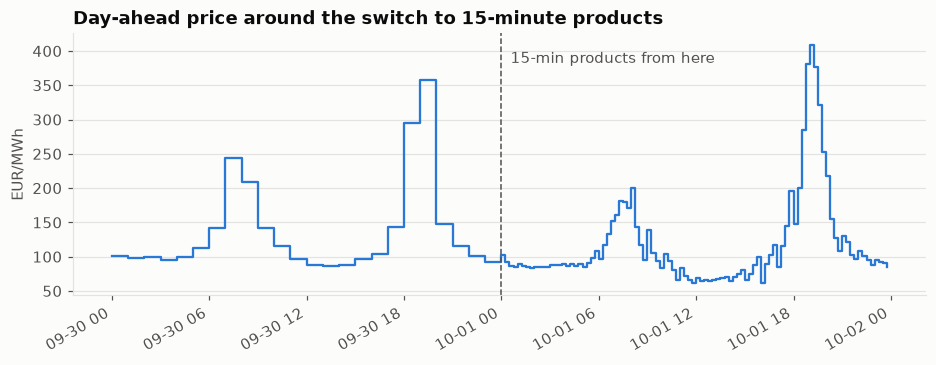

In [2]:
raw = data.fetch_day_ahead_prices("2025-09-30", "2025-10-01")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.step(raw.index, raw, where="post", color=C["price"])
ax.axvline(data.DA_15MIN_START, color=plotting.INK_MUTED, lw=1, ls="--")
ax.annotate("15-min products from here", (data.DA_15MIN_START, raw.max()),
            xytext=(6, -4), textcoords="offset points", va="top", color=plotting.INK_MUTED)
ax.set(title="Day-ahead price around the switch to 15-minute products", ylabel="EUR/MWh")
fig.autofmt_xdate()

,mean price,mean daily spread,negative hours
2023,95.2,97.9,301.0
2024,78.5,111.2,457.0
2025,89.3,130.4,574.8
2026,112.2,181.8,463.5


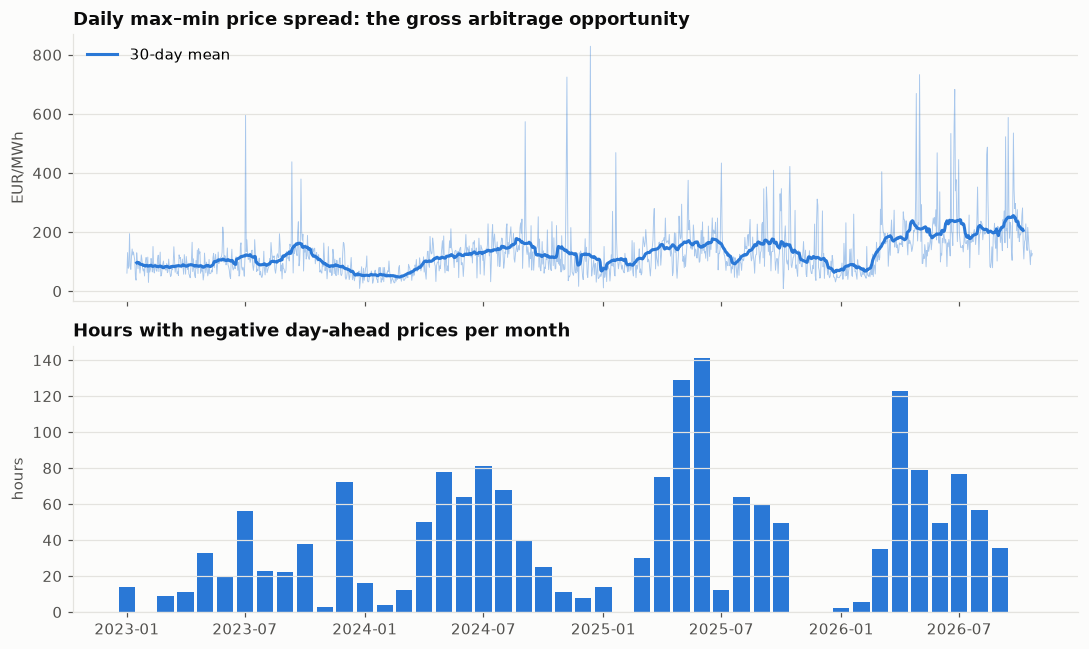

In [3]:
p = df.price_eur_mwh
daily = p.groupby(p.index.date).agg(["min", "max", "mean"])
daily.index = pd.to_datetime(daily.index)
daily["spread"] = daily["max"] - daily["min"]
neg_hours = (p < 0).resample("MS").sum() / 4

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(daily.index, daily.spread, color=C["price"], lw=0.6, alpha=0.4)
ax1.plot(daily.spread.rolling(30, center=True).mean(), color=C["price"], lw=2, label="30-day mean")
ax1.set(title="Daily max–min price spread: the gross arbitrage opportunity", ylabel="EUR/MWh")
ax1.legend(loc="upper left")
ax2.bar(neg_hours.index, neg_hours, width=25, color=C["price"])
ax2.set(title="Hours with negative day-ahead prices per month", ylabel="hours")
fig.tight_layout()

summary = pd.DataFrame({
    "mean price": p.groupby(p.index.year).mean(),
    "mean daily spread": daily.spread.groupby(daily.index.year).mean(),
    "negative hours": (p < 0).groupby(p.index.year).sum() / 4,
}).round(1)
summary

Note the 2026 numbers are year-to-date. Spreads and negative-price hours peak in late spring and
summer: midday solar pushes prices down, evening ramps push them up.

## The site: load, PV and price on a typical day

Average daily profiles by season. Price and power have different units, so they get separate panels
rather than a second y-axis.

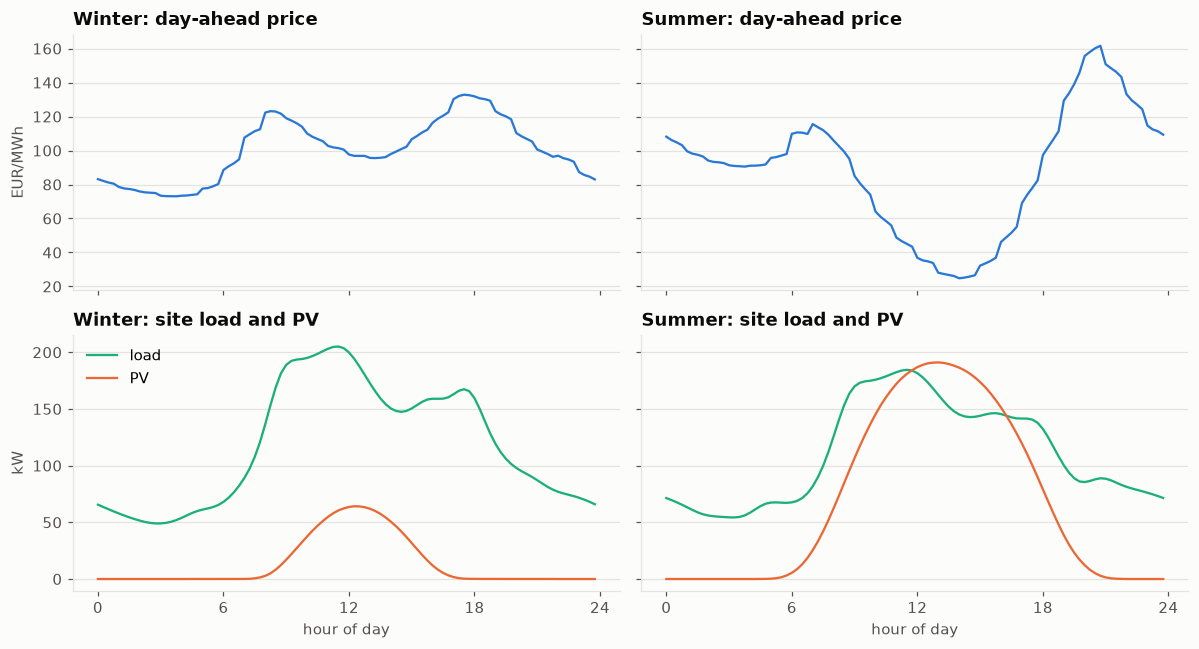

In [4]:
season = df.index.month.map({12: "winter", 1: "winter", 2: "winter", 6: "summer", 7: "summer", 8: "summer"})
sub = df[season.notna()].assign(season=season.dropna(), tod=lambda d: d.index.hour + d.index.minute / 60)
prof = sub.groupby(["season", "tod"])[["price_eur_mwh", "load_kw", "pv_kw"]].mean()

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey="row")
for col, s in enumerate(["winter", "summer"]):
    d = prof.loc[s]
    axes[0, col].plot(d.index, d.price_eur_mwh, color=C["price"])
    axes[0, col].set_title(f"{s.capitalize()}: day-ahead price")
    axes[1, col].plot(d.index, d.load_kw, color=C["load"], label="load")
    axes[1, col].plot(d.index, d.pv_kw, color=C["pv"], label="PV")
    axes[1, col].set_title(f"{s.capitalize()}: site load and PV")
axes[0, 0].set_ylabel("EUR/MWh"); axes[1, 0].set_ylabel("kW")
axes[1, 0].legend(loc="upper left")
for ax in axes[1]:
    ax.set_xticks(range(0, 25, 6)); ax.set_xlabel("hour of day")
fig.tight_layout()

In [5]:
energy = (df.groupby(df.index.year)[["load_kw", "pv_kw"]].sum() / 4 / 1e3).rename(
    columns={"load_kw": "load MWh", "pv_kw": "PV MWh"})
surplus = (df.pv_kw - df.load_kw).clip(lower=0)
energy["PV surplus MWh"] = surplus.groupby(df.index.year).sum() / 4 / 1e3
energy["PV full-load h"] = energy["PV MWh"] * 1e3 / site.pv_kwp
energy["peak load kW"] = df.load_kw.groupby(df.index.year).max()
energy.round(1)

,load MWh,PV MWh,PV surplus MWh,PV full-load h,peak load kW
2023,1000.0,400.8,61.8,1002.0,240.2
2024,1000.0,364.5,44.4,911.2,239.3
2025,1000.0,360.7,38.0,901.9,240.0
2026,798.7,356.8,43.5,892.1,239.5


## Takeaways for the optimization

* **Arbitrage value is mostly a midday-vs-evening play** and is concentrated in spring and summer. The
  same hours carry the site's PV surplus, so a behind-the-meter battery doubles up on them.
* **Negative prices are common** (hundreds of hours a year). An LP battery model can then profit from
  charging and discharging at once to burn energy; we deal with that explicitly (MILP or argument) in phase 2.
* **15-minute resolution from Oct 2025**: the models run on a 15-minute grid throughout, so both regimes
  are handled the same way.
* **Caveats of the synthetic site**: the SLP is a smooth average without the noise or the occasional
  spikes that drive demand charges in reality, and the PV profile is national, i.e. smoother than one
  rooftop. Both make the forecasting problem in phase 4 easier than reality.